# HW4 – Can a simple stock strategy beat the S&P 500?

Mila Marsot

Every month, I buy a group of stocks, keep each one for 90 days, and compare the result with buying the S&P 500. I make all my choices on 2012–2015, each time keeping the option with the best Sharpe ratio. Then I test the final strategy once, on April 2016 – September 2026.

The data and the Ridge model come from the course code (`course_data.py`). The backtester is my own code.

To run it: `uv sync --locked`, put the bCourses databases in `Lectures/modeling/data/`, then *Run All* with the `.venv` kernel.

## Settings

In [3]:
import sys
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge

# As in the Lecture 7 and 8 notebooks, I use the course functions in Lectures/modeling/course_data.py
sys.path.insert(0, "../../../Lectures/modeling")
from course_data import (load_data, load_membership, price_features, financial_events,
                         join_financials, apply_membership, make_labels, make_pipeline, FEATURES)

DATABASE = "equities_top2000.duckdb"
# DATABASE = "equities_class.duckdb" # small database

DB_PATH = Path("../../../Lectures/modeling/data") / DATABASE

if DATABASE == "equities_top2000.duckdb":
    PAST_START, PAST_END = "2012-01-01", "2015-12-31" # I make my decisions here
    TEST_START, TEST_END = "2016-04-01", "2026-09-30" # final test
else:
    PAST_START, PAST_END = "2012-01-01", "2014-12-31"
    TEST_START, TEST_END = "2015-01-01", "2015-12-31"

START_CASH = 1_000_000 # dollars
FEE = 0.0005 # 0.05% for each buy and each sell

## Building the data

I build a table with one row per stock at the end of each month. Each row says what I knew that day (recent price moves, latest published financial results, sector) and what happened next: `target` is the return from buying at the next close and selling 90 days later, and `label_end` is the day this return became known. A stock is only kept if it was in the universe of that quarter, even if it disappeared later.

I use the course functions, 200 stocks at a time because the database is big.

In [4]:
# Open the database (read only, so nothing can be changed by mistake)
con = duckdb.connect(str(DB_PATH), read_only=True)

# The list of all the stocks in the database
all_stocks = con.sql("SELECT symbol FROM universe ORDER BY symbol").df().symbol.tolist()

# The list of stocks chosen each quarter (the universe)
membership = load_membership(DB_PATH, end=TEST_END)

# The database is big, so I work on 200 stocks at a time
pieces = []
for i in range(0, len(all_stocks), 200):
    group = all_stocks[i:i + 200]

    prices_group, financials, sectors, calendar = load_data(DB_PATH, end=TEST_END, symbols=group)
    days = pd.DatetimeIndex(calendar.date)

    # Add the columns I need, with the course functions
    rows = price_features(prices_group, days) # past price moves
    rows = join_financials(rows, financial_events(financials), sectors) # latest published results, sector
    rows = apply_membership(rows, membership, days) # can I buy this stock?
    rows = make_labels(rows, prices_group, days) # what happens over the next 90 days

    # Keep only the last trading day of each month, from 2010, for stocks I can buy
    month_ends = days.to_series().groupby(days.to_period("M")).max()
    keep = rows.date.isin(month_ends) & (rows.date >= "2010-01-01") & rows.eligible
    pieces.append(rows[keep])

# Put the 200-stock pieces back together, sorted by date
data = pd.concat(pieces).sort_values(["date", "symbol"]).reset_index(drop=True)

# Quick look at the result
print(len(data), "rows")
data[["date", "symbol", "momentum_63", "volatility_63", "entry_date", "target"]].head()

/var/folders/kt/r5c6m0811mq_qd9gfd4hm9fm0000gn/T/ipykernel_47033/386972706.py:15: UserWarning: Quarantining 275 invalid adjusted-price rows; inspect the raw database and delivery audit.
  prices_group, financials, sectors, calendar = load_data(DB_PATH, end=TEST_END, symbols=group)
/var/folders/kt/r5c6m0811mq_qd9gfd4hm9fm0000gn/T/ipykernel_47033/386972706.py:15: UserWarning: Quarantining 3 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
  prices_group, financials, sectors, calendar = load_data(DB_PATH, end=TEST_END, symbols=group)
/var/folders/kt/r5c6m0811mq_qd9gfd4hm9fm0000gn/T/ipykernel_47033/386972706.py:15: UserWarning: Quarantining 4 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
  prices_group, financials, sectors, calendar = load_data(DB_PATH, end=TEST_END, symbols=group)
/var/folders/kt/r5c6m0811mq_qd9gfd4hm9fm0000gn/T/ipykernel_47033/386972706.py:15: UserWarning: Quarantining 7 price ro

395345 rows


,date,symbol,momentum_63,volatility_63,entry_date,target
0,2010-01-29,A,0.106742,0.247376,2010-02-01,0.262073
1,2010-01-29,AAIC,0.292808,0.431588,2010-02-01,0.408145
2,2010-01-29,AAL,0.696485,0.709334,2010-02-01,0.319643
3,2010-01-29,AAN,0.117978,0.246331,2010-02-01,-0.187970
4,2010-01-29,AAON,0.136508,0.306528,2010-02-01,0.187675


I also need the daily prices (for the backtester) and the S&P 500 (to compare).

In [5]:
daily = con.execute("""SELECT symbol, date, adj_close FROM prices
                       WHERE date >= ? AND date <= ? AND adj_close > 0
                       AND date IN (SELECT date FROM calendar)""", [PAST_START, TEST_END]).df()
prices = daily.pivot(index="date", columns="symbol", values="adj_close") # one row per day, one column per stock

sp500 = con.execute("SELECT date, adj_close FROM benchmark WHERE date >= ? AND date <= ?",
                    [PAST_START, TEST_END]).df()
sp500 = sp500.set_index("date").adj_close

## I give a score to each stock

Each month, I rank the stocks with a score: the higher the score, the more I want the stock. I try three scores and choose one in Decision 1.

- `score_mom3`: the rise over the last 3 months.
- `score_mom12`: the rise over the last 12 months, without the last month (the classic momentum).
- `score_model`: the 90-day return predicted by the Ridge model of Lecture 7, with all the course features. Ridge is simple, linear, and stays stable when several features say almost the same thing. I keep the course setting (`alpha = 100`).

In [6]:
# The two momentum scores are already columns of the data
data["score_mom3"] = data.momentum_63
data["score_mom12"] = data.momentum_252_21

The model only learns from returns that were already known: before 2012 for my decisions, and before the first test signal (end of March 2016) for the final test. It does not change after that.

In [7]:
# Model for the past period
train_past = data[data.label_end < PAST_START]
past_model = make_pipeline(Ridge(alpha=100))
past_model.fit(train_past[FEATURES], train_past.target)

# Model for the final test
first_test_day = data.date[data.entry_date >= TEST_START].min()
train_test = data[data.label_end < first_test_day]
test_model = make_pipeline(Ridge(alpha=100))
test_model.fit(train_test[FEATURES], train_test.target)

# Each row gets the score of the right model
data["score_model"] = past_model.predict(data[FEATURES])
in_test = data.date >= first_test_day
data.loc[in_test, "score_model"] = test_model.predict(data.loc[in_test, FEATURES])

## The backtester

At the end of each month, I pick the stocks with the best score and buy them at the next day's close, since my score uses today's close. Each month I invest at most a third of the portfolio, so I hold about three monthly groups at once. Each buy and each sell costs 0.05%, I never borrow, and my cash earns no interest. These rules follow Lecture 8 (`MonthlyTopNStrategy`, and the fee of `size_for_budget`).

### Which stocks, and how much money?

`make_orders` gives, for each buying day, the stocks to buy and the share of the monthly budget for each one. Its four settings are my four decisions: the score, the number of stocks, the share of very volatile stocks left out, and how the money is split (equally, more for the best ranks, or more for the calmest stocks).

In [8]:
def make_orders(score, n_stocks, remove_share, weighting, start, end):
    orders = {}

    # I only look at the months between start and end
    candidates = data[(data.entry_date >= start) & (data.entry_date <= end)]

    # I go through the months one by one
    for buy_date, stocks in candidates.groupby("entry_date"):

        # First, I leave out the most volatile stocks of the month
        volatility_rank = stocks.volatility_63.rank(pct=True) # from 0 (calmest) to 1 (most volatile)
        stocks = stocks[volatility_rank <= 1 - remove_share]

        # Then I keep the stocks with the best scores
        chosen = stocks.nlargest(n_stocks, score)

        # I decide how much each stock should get
        if weighting == "equal":
            # every stock gets the same weight
            weight = pd.Series(1.0, index=chosen.index)
        elif weighting == "by score rank":
            # the best stock gets n points, the next one n - 1, ..., the last one 1
            weight = pd.Series(range(len(chosen), 0, -1), index=chosen.index, dtype=float)
        elif weighting == "calm stocks get more":
            # a stock that moves twice as much gets half as much money
            weight = 1 / chosen.volatility_63

        # Finally, I turn the weights into shares of the monthly budget (they add up to 100%)
        share = weight / weight.sum()
        orders[buy_date] = dict(zip(chosen.symbol, share))     # {stock: share}

    return orders

Each day, `run_backtest` sells the purchases that are 90 days old, buys the planned stocks, and counts the portfolio value (cash + stocks). The monthly budget uses the cash of the previous close, because the money of today's sales only arrives at today's close.

I never invent a price: a stock with no price on the buying day is skipped, and a stock that stops trading stays at its last price and is never sold.

In [9]:
def run_backtest(orders, start, end):
    # The market days of the period, and the last known price of each stock on each day
    days = prices.loc[start:end].index
    last_price = prices.loc[start:end].ffill()

    # At the start, I only have cash
    cash = START_CASH
    portfolio_value = START_CASH # what my portfolio was worth at the last close
    cash_last_close = START_CASH # the cash I had at the last close
    lots = [] # my purchases still in the portfolio
    trades = [] # a record of every buy and every sell
    values = {} # the value of my portfolio each evening

    for day in days:

        # I sell the stocks I have held for 90 days
        still_held = []
        for lot in lots:
            price = prices.at[day, lot["stock"]]
            days_held = (day - lot["buy_date"]).days
            if days_held >= 90 and price > 0:
                # sold at today's close, minus the fee
                money_in = lot["shares"] * price * (1 - FEE)
                cash = cash + money_in
                trades.append({"date": day, "side": "sell", "stock": lot["stock"],
                               "cash_change": money_in, "days_held": days_held})
            else:
                # not 90 days yet, or no price today: I keep it
                still_held.append(lot)
        lots = still_held

        # If today is a buying day, I buy the planned stocks
        if day in orders:
            # at most a third of the portfolio, and never more than the cash I had at the last close
            # (the money from today's sales only arrives at today's close, so I can't know it when I decide)
            month_budget = min(cash_last_close, portfolio_value / 3)
            for stock, share in orders[day].items():
                budget = month_budget * share
                price = prices.at[day, stock] if stock in prices.columns else np.nan
                # I need a price today, and at least $1 to spend
                if price > 0 and budget >= 1:
                    shares = budget / (price * (1 + FEE))    # the fee is included in the budget
                    cash = cash - budget
                    lots.append({"stock": stock, "buy_date": day, "shares": shares})
                    trades.append({"date": day, "side": "buy", "stock": stock,
                                   "cash_change": -budget, "days_held": 0})

        # In the evening, I count what my portfolio is worth
        holdings = 0
        for lot in lots:
            holdings = holdings + lot["shares"] * last_price.at[day, lot["stock"]]
        portfolio_value = cash + holdings
        cash_last_close = cash
        values[day] = portfolio_value

    return pd.Series(values), pd.DataFrame(trades), lots

### Measuring the results

I use the final value, the CAGR (average return per year), the maximum drawdown (worst fall from a peak) and the Sharpe ratio (return above 2% per year, divided by the risk; higher is better).

In [10]:
def stats(value):
    # How the portfolio moved each day, and how many years the period lasts
    daily_return = value.pct_change().dropna()
    years = (value.index[-1] - value.index[0]).days / 365.25

    # Final value: how much money I end up with
    final_value = value.iloc[-1]

    # CAGR: the average return per year
    cagr = (final_value / START_CASH) ** (1 / years) - 1

    # Max drawdown: the worst drop from a previous high point
    highest_so_far = value.cummax()
    max_drawdown = (value / highest_so_far - 1).min()

    # Sharpe: the daily return above a safe 2% per year, divided by the daily risk, then put on a yearly scale
    sharpe = (daily_return.mean() - 0.02 / 252) / daily_return.std() * np.sqrt(252)

    return pd.Series({"Final value": round(final_value), "CAGR": round(cagr, 3),
                      "Max drawdown": round(max_drawdown, 3), "Sharpe": round(sharpe, 2)})


def sp500_value(start, end):
    # What $1,000,000 put in the S&P 500 on the first day would be worth each day
    index = sp500.loc[start:end]
    return START_CASH * index / index.iloc[0]

`try_on_past` runs one option on 2012–2015, and `compare` shows the options next to the S&P 500, in a chart and a table.

In [11]:
def try_on_past(score, n_stocks, remove_share, weighting):
    orders = make_orders(score, n_stocks, remove_share, weighting, PAST_START, PAST_END)
    value, trades, lots = run_backtest(orders, PAST_START, PAST_END)
    return value


def compare(results, title):
    results["S&P 500"] = sp500_value(PAST_START, PAST_END)
    pd.DataFrame(results).plot(title=title, figsize=(9, 4), ylabel="Portfolio value ($)")
    table = pd.DataFrame({name: stats(value) for name, value in results.items()}).T
    return table

## Decision 1: which score?

I try the three scores with everything else fixed: 20 stocks per month, no stock left out, equal amounts.

I choose: score_mom12


,Final value,CAGR,Max drawdown,Sharpe
score_mom3,1.676773e+06,0.138,-0.340,0.46
score_mom12,1.896310e+06,0.174,-0.374,0.64
score_model,4.928018e+09,7.415,-0.319,0.50
S&P 500,1.743113e+06,0.149,-0.120,1.00


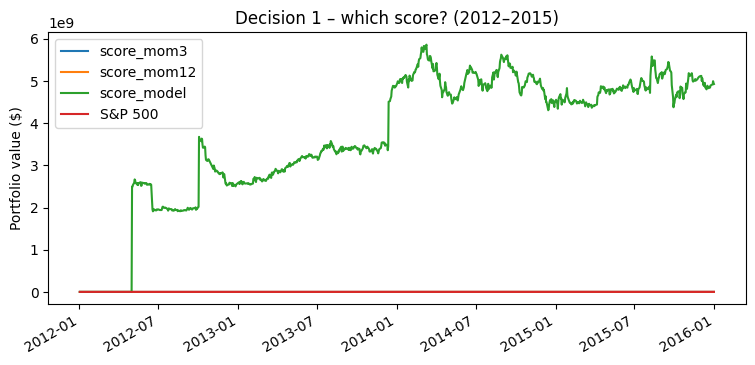

In [12]:
# I run the strategy once with each score
results = {}
for score in ["score_mom3", "score_mom12", "score_model"]:
    results[score] = try_on_past(score, 20, 0, "equal")

# I compare them with the S&P 500, and I keep the score with the best Sharpe
table = compare(results, "Decision 1 – which score? (2012–2015)")
best_score = table.drop("S&P 500").Sharpe.idxmax()
print("I choose:", best_score)
table

The $4.9 billion of the course model is not real: it comes from wrong prices in the database (see the findings). Its Sharpe is lower anyway, so it is not chosen.

## Decision 2: how many stocks per month?

Fewer stocks put more money on my best ideas; more stocks spread the risk. I try 10, 20 and 50.

Stocks per month: 50


,Final value,CAGR,Max drawdown,Sharpe
10,2050798.0,0.197,-0.417,0.54
20,1896310.0,0.174,-0.374,0.64
50,2122410.0,0.207,-0.216,0.84
S&P 500,1743113.0,0.149,-0.120,1.00


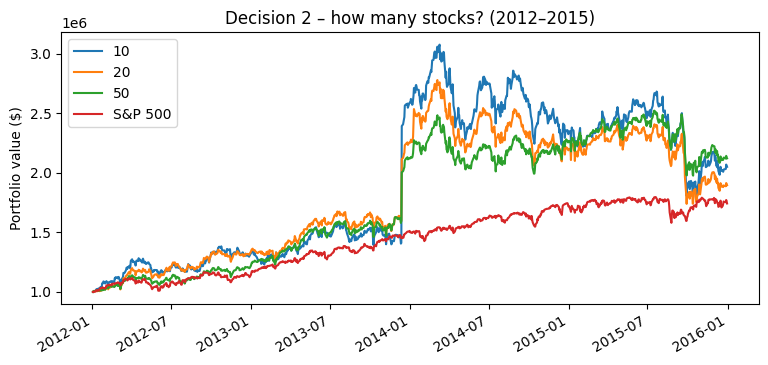

In [13]:
# I run the strategy with 10, 20 and 50 stocks per month
results = {}
for n in [10, 20, 50]:
    results[n] = try_on_past(best_score, n, 0, "equal")

# I keep the number of stocks with the best Sharpe
table = compare(results, "Decision 2 – how many stocks? (2012–2015)")
n_stocks = table.drop("S&P 500").Sharpe.idxmax()
print("Stocks per month:", n_stocks)
table

## Decision 3: how many of the riskiest stocks do I remove?

Very volatile stocks can jump, but they can also crash. Before ranking, I leave out 0%, 5%, 10% or 20% of the most volatile stocks (`volatility_63`).

Share of the riskiest stocks removed: 0.1


,Final value,CAGR,Max drawdown,Sharpe
0,2122410.0,0.207,-0.216,0.84
0.05,2411339.0,0.247,-0.186,1.05
0.1,2170288.0,0.214,-0.149,1.12
0.2,1678047.0,0.138,-0.113,0.86
S&P 500,1743113.0,0.149,-0.120,1.00


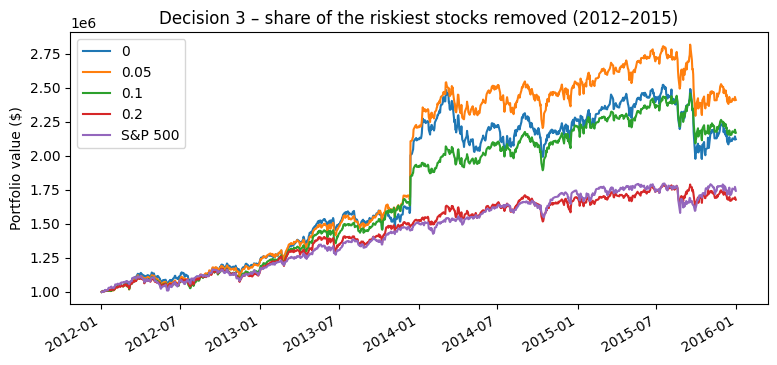

In [14]:
# I run the strategy with 0%, 5%, 10% and 20% of the most volatile stocks left out
results = {}
for remove_share in [0, 0.05, 0.10, 0.20]:
    results[remove_share] = try_on_past(best_score, n_stocks, remove_share, "equal")

# I keep the share with the best Sharpe
table = compare(results, "Decision 3 – share of the riskiest stocks removed (2012–2015)")
remove_share = table.drop("S&P 500").Sharpe.idxmax()
print("Share of the riskiest stocks removed:", remove_share)
table

## Decision 4: how do I split the money?

I try the three ways of `make_orders`: equal amounts, more money on the best ranks, or more money on the calmest stocks.

Split of the money: equal


,Final value,CAGR,Max drawdown,Sharpe
equal,2170288.0,0.214,-0.149,1.12
by score rank,2162864.0,0.213,-0.163,1.02
calm stocks get more,2044965.0,0.196,-0.139,1.07
S&P 500,1743113.0,0.149,-0.120,1.00


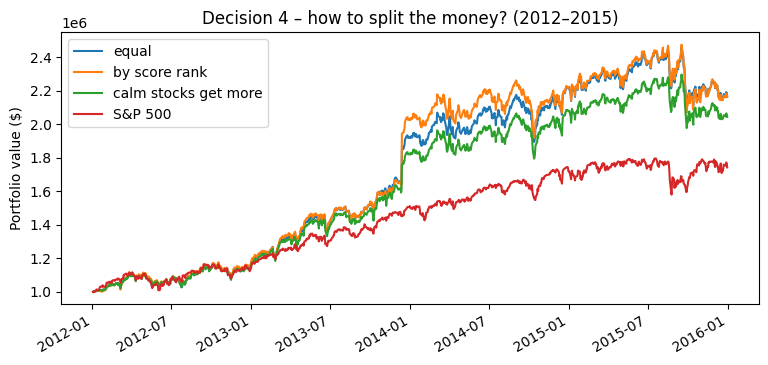

In [15]:
# I run the strategy with the three ways of splitting the money
results = {}
for weighting in ["equal", "by score rank", "calm stocks get more"]:
    results[weighting] = try_on_past(best_score, n_stocks, remove_share, weighting)

# I keep the split with the best Sharpe
table = compare(results, "Decision 4 – how to split the money? (2012–2015)")
weighting = table.drop("S&P 500").Sharpe.idxmax()
print("Split of the money:", weighting)
table

I keep trading once a month, as in Lecture 8 (not tested). Here is my final strategy, which I don't change anymore:

In [16]:
# The four choices made on 2012–2015
print("Score:", best_score)
print("Stocks per month:", n_stocks)
print("Riskiest stocks removed:", f"{remove_share:.0%}")
print("Split of the money:", weighting)

Score: score_mom12
Stocks per month: 50
Riskiest stocks removed: 10%
Split of the money: equal


## Final test: April 2016 – September 2026

I run the final strategy once, against $1,000,000 put in the S&P 500 at the first test close. The stocks still held at the end count at their last price.

,Final value,CAGR,Max drawdown,Sharpe
My strategy,2634120.0,0.097,-0.388,0.45
S&P 500,4402747.0,0.152,-0.338,0.77


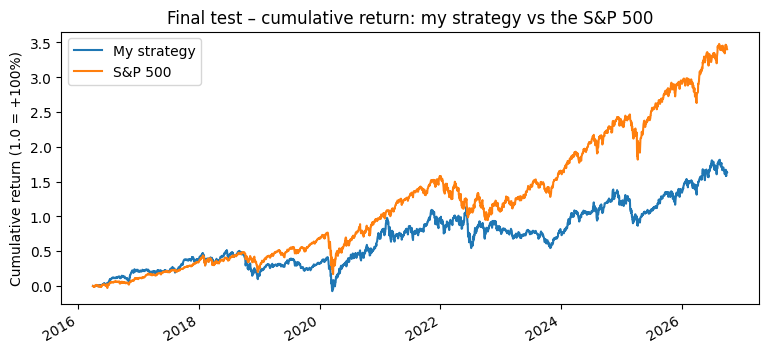

In [17]:
# I prepare the orders of the test period and run the backtester
orders = make_orders(best_score, n_stocks, remove_share, weighting, TEST_START, TEST_END)
value, trades, lots = run_backtest(orders, TEST_START, TEST_END)

# My strategy and the S&P 500, over the same days
final = {"My strategy": value, "S&P 500": sp500_value(TEST_START, TEST_END)}

# The cumulative return of both portfolios on one chart (0.5 = +50% since the start)
cumulative_return = pd.DataFrame(final) / START_CASH - 1
cumulative_return.plot(title="Final test – cumulative return: my strategy vs the S&P 500",
                       figsize=(9, 4), ylabel="Cumulative return (1.0 = +100%)")

# The four measures for both portfolios
pd.DataFrame({name: stats(v) for name, v in final.items()}).T

### Checks

I check the accounting with numbers I can recompute: the first purchase, the final value rebuilt from the list of trades, and the rules (no negative cash, 90 days held, buying after the signal, no trade after the end).

In [18]:
# The list of buys and the list of sells
buys = trades[trades.side == "buy"]
sells = trades[trades.side == "sell"]

# 1. The first purchase should be 1,000,000 / 3 × the share of this stock in the first month
first = buys.iloc[0]
expected = START_CASH / 3 * orders[first["date"]][first["stock"]]
print("First purchase:", round(-first["cash_change"]), "$ | expected:", round(expected), "$")

# 2. The cash from the list of trades + the stocks still held should give the final value
cash_at_end = START_CASH + trades.cash_change.sum()
last_prices = prices.loc[:TEST_END].ffill().iloc[-1]
held_at_end = sum(lot["shares"] * last_prices[lot["stock"]] for lot in lots)
assert abs(cash_at_end + held_at_end - value.iloc[-1]) < 0.01

# 3. The rules should be respected
test_rows = data[(data.entry_date >= TEST_START) & (data.entry_date <= TEST_END)]
cash_after_each_trade = START_CASH + trades.cash_change.cumsum()
assert cash_after_each_trade.min() > -0.01             # cash never negative (no borrowing)
assert sells.days_held.min() >= 90                     # every stock kept at least 90 days
assert (test_rows.entry_date > test_rows.date).all()   # I always buy after the signal day
assert trades.date.max() <= pd.Timestamp(TEST_END)     # no trade after the end of the test

print("All checks passed.", len(buys), "buys,", len(sells), "sells,", len(lots), "stocks still held at the end.")
print(f"Final value = cash {cash_at_end:,.0f} $ + stocks held {held_at_end:,.0f} $")

First purchase: 6667 $ | expected: 6667 $
All checks passed. 5996 buys, 5854 sells, 142 stocks still held at the end.
Final value = cash 812,232 $ + stocks held 1,821,887 $


I also give the same orders to the Lecture 8 backtester (`backtest.py`) and check that it finds the same value every day. This only checks my accounting: the orders come from my strategy, and my results come from my backtester. Like mine, it keeps stocks without a price (I raise its 5-day limit).

In [19]:
sys.path.insert(0, "../../../Lectures/modeling")
from backtest import Strategy, Backtester, OrderManagementSystem


class MyOrders(Strategy):
    # A strategy for the course backtester that simply returns my orders
    def __init__(self, orders):
        super().__init__(holding_days=90)
        self.orders = orders

    def generate_orders(self, signal_date, execution_date, portfolio, history):
        if execution_date not in self.orders:
            return pd.Series(dtype=float)
        # same budget as mine: at most a third of the portfolio, and never more than the cash of the last close
        month_budget = min(portfolio.cash, portfolio.nav / 3)
        return pd.Series(self.orders[execution_date]) * month_budget


class CourseBacktester(Backtester):
    # My orders are already prepared, so the strategy does not need the price history (this makes it faster)
    def market_history(self, signal_date):
        return None


# The course backtester wants the prices as a list of (date, symbol, price), on market days only
course_prices = daily[pd.to_datetime(daily.date).isin(sp500.index)]
course_sp500 = sp500.rename("adj_close").reset_index()

course = CourseBacktester(course_prices, course_sp500, MyOrders(orders),
                          OrderManagementSystem(initial_cash=START_CASH, fee_bps=FEE * 10_000),
                          max_stale_sessions=10**6) # I keep stocks without a price, as in my backtester
course_value = course.run_backtest(TEST_START, TEST_END).history.nav.iloc[1:] # the first row is the start, before any trade

assert (course_value.index == value.index).all()
assert np.allclose(course_value, value)
print(f"Same value every day as the course backtester. Final value: mine {value.iloc[-1]:,.2f} $ | course {course_value.iloc[-1]:,.2f} $")


Same value every day as the course backtester. Final value: mine 2,634,119.71 $ | course 2,634,119.71 $


### A few numbers to understand the result

In [20]:
# The rows of the stocks I really bought
bought = test_rows.merge(buys, left_on=["entry_date", "symbol"], right_on=["date", "stock"])

# Did my stocks do better than the others? Were they riskier?
print(f"Median 90-day return - stocks I bought: {bought.target.median():.1%} | all stocks: {test_rows.target.median():.1%}")
print(f"Volatility - stocks I bought: {bought.volatility_63.mean():.0%} | all stocks: {test_rows.volatility_63.mean():.0%}")

# My worst moment
print(f"Lowest portfolio value: {value.min():,.0f} $ on {value.idxmin().date()}")

# The share of the portfolio that waits in cash, on average
cash_each_day = START_CASH + trades.groupby("date").cash_change.sum().reindex(value.index, fill_value=0).cumsum()
print(f"Average share of the portfolio in cash: {(cash_each_day / value).mean():.0%}")

# The money stuck in stocks that stopped trading (no price in the last 10 days of the test)
traded_recently = prices.loc[:TEST_END].tail(10).notna().any()
stuck = sum(lot["shares"] * prices[lot["stock"]].dropna().iloc[-1]
            for lot in lots if not traded_recently[lot["stock"]])
print(f"Money stuck in stocks that stopped trading: {stuck:,.0f} $ ({stuck / value.iloc[-1]:.0%} of the final value)")

# The stocks I bought most often
print("Most bought stocks:", buys.stock.value_counts().head(8).to_dict())

Median 90-day return - stocks I bought: 1.3% | all stocks: 2.0%
Volatility - stocks I bought: 46% | all stocks: 40%
Lowest portfolio value: 924,927 $ on 2020-03-18
Average share of the portfolio in cash: 19%
Money stuck in stocks that stopped trading: 514,918 $ (20% of the final value)
Most bought stocks: {'NVDA': 44, 'TPL': 25, 'RNG': 21, 'FIVN': 21, 'MOD': 19, 'FRPT': 18, 'STRL': 18, 'SKYW': 18}


## Findings

### My strategy did not beat the S&P 500

| April 2016 – September 2026 | My strategy | S&P 500 |
|---|---:|---:|
| Final value | $2,634,120 | $4,402,747 |
| CAGR | 9.7% | 15.2% |
| Max drawdown | −38.8% | −33.8% |
| Sharpe ratio | 0.45 | 0.77 |

My strategy multiplied the money by 2.6, but in the end it has $1.77 million less than the S&P 500. This is about 5.5 points less per year. Its drawdown is also deeper and its Sharpe ratio is lower.

### Why

First, what worked in the past did not work in the test. On 2012–2015, my strategy was better than the S&P 500 (CAGR 21.4% against 14.9%). But I chose the best options on these same four years, so part of this result was probably luck.

Second, my gains come from a few very good stocks. The median stock I bought made 1.3% in 90 days, less than the median stock (2.0%). For example, I bought NVDA 44 times.

Third, a part of my money did not work. 20% of the final value ($514,918) is in stocks that stopped trading, often because another company bought them. The database has no price for this, so I can never use this money again. Also, on average 19% of my portfolio was in cash. For example, a stock bought on January 2 is sold on April 2, one day after the April purchases, so this money waits until May.

Fourth, I give the same amount to each stock. The S&P 500 gives more money to the biggest companies, and they did very well in 2016–2026.

Finally, my strategy was more risky: its worst drawdown was −38.8%, against −33.8% for the S&P 500.

### What I learned from the decisions

On 2012–2015, 12-month momentum had the best Sharpe (0.64). 50 stocks was better than 10 or 20. I think my score does not separate well the good and the bad stocks, so it is better to spread the money. Removing the 10% most volatile stocks helped (Sharpe 1.12), but removing 20% also removed good stocks. Giving the same amount to each stock was the best choice: giving more to the best scores only added risk.

### Data problems and bugs

Some prices in the database are wrong. For example, the price of AAM is multiplied by 135,000 in one day in 2012, which is impossible. The course model bought this stock, so it shows a fake result of $4.9 billion in Decision 1. The course functions removed 275 other wrong prices (these are the warnings at the start), but not this one, because it is positive.

My checks also found two bugs in my backtester. First, when there was no cash left, it made purchases of $0. Now it only buys if there is at least $1. Second, it used the money of a sale to buy other stocks on the same day. For example, on November 2, it sold a stock at the close and used this money to buy new stocks at the same close. But I decide my purchases before the close, so I cannot know yet how much the sale will give. Now the budget uses the cash of the evening before, like the course backtester. With this correction, my final value went down from $3,285,980 to $2,634,120: the correction made my result worse, so I did not make it to get a better result. My four decisions did not change.

### Limits

There is no limit by sector, the costs are simple (0.05% per trade), and the cash earns no interest. When a company disappears, I have no price for it. Each decision was tested on only four years, one decision at a time, and the Ridge model was trained only once before each period, with the course settings.

### What I tried first

| April 2016 – September 2026 | Course model, 20 stocks | Simple 3-feature model, 50 stocks | 12-month momentum, 50 stocks, 20% riskiest removed |
|---|---:|---:|---:|
| Final value | $1,320,486 | $1,184,077 | $2,645,297 |
| CAGR | 2.7% | 1.6% | 9.7% |
| Max drawdown | −67.5% | −69.0% | −47.0% |

I ran my first two models directly on the test period. They bought mostly very volatile stocks (crypto miners, "meme stocks"). So I built the strategy again, step by step, on 2012–2015. In my first step-by-step version (last column), I chose the share of risky stocks before the number of stocks. Then I changed the order and I added more options. These three tests used my backtester before the cash correction, so their results are a bit too good.

After the final test, I also tried to buy every week instead of every month (1/13 of the portfolio each week), only on the small class database. Less cash was waiting (10% instead of 23%), but the Sharpe on 2012–2014 was lower (1.14–1.27 against 1.45). So I kept buying once a month.

To be honest, I built this method after seeing my first test results, so my final test is not perfectly clean. To limit this problem, I made every decision on 2012–2015 only, and I stop here.

### What I would try next

First, I would clean the prices. I would also use the cash paid when a company is bought, if the data exists. I would try to use the cash that waits, for example by buying as soon as a sale gives money back, or by investing a quarter of the portfolio each month. Then I would add a limit by sector, give more money to big companies, and test my decisions on more years, with a new training of the model every year.

I used AI (Claude) to understand the lecture functions and how to use them in my strategy, to review my code, and to write and simplify the text. It also found the cash bug, and it wrote the fix, the comparison cell, and the cash check. 